# Detecting Declining Customer Engagement for Proactive Telecom Retention

People don't usually leave a telecom operator overnight. They use the phone less for a while and then they're gone. If that pattern shows up in the data, the operator gets a window to contact them before they leave.

This notebook uses customer data from an anonymised operator (Company A) to answer three questions:

1. Do customers whose voice usage, call activity or spending is falling churn more often?
2. Does measuring that decline improve churn prediction beyond tenure, handset age and usage levels?
3. How could a risk ranking guide retention spending, and what would a campaign have to cost to pay off?

I go from data checks to EDA, feature design, modelling, a customer risk ranking and an impact estimate. The business and market side is in the slides.

## 1. Data

There are two tables with 100,000 customers each, joined on `Customer_ID`. `Client` has account and household details, handset info, lifetime totals and the 3- and 6-month usage averages. `Record` has recent monthly usage, call quality, customer-care contact, `change_mou`, `change_rev`, tenure (`months`) and the churn label, which flags customers who left 31-60 days after the observation date.

In [22]:
# Data and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Evaluation and interpretation
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

In [23]:
import gdown

client_url = "https://drive.google.com/uc?id=1Y6Arg2NdtJWqreQ8hRlbMpaJoYpUb526"
record_url = "https://drive.google.com/uc?id=1DZZMYp3r7ilpvIy_c9bluc0Fzj-ZnnbF"

gdown.download(client_url, "Client.csv", quiet=True)
gdown.download(record_url, "Record.csv", quiet=True)

client_df = pd.read_csv("Client.csv")
record_df = pd.read_csv("Record.csv")
print("Client table:", client_df.shape, "| Record table:", record_df.shape)

print("\nClient table (first rows)")
display(client_df.head())

print("Record table (first rows)")
display(record_df.head())

Client table: (100000, 50) | Record table: (100000, 51)

Client table (first rows)


,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0,1000005


Record table (first rows)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005


### Integrity and missing values

Before merging, I check that every `Customer_ID` is unique in its table and appears in both, so the join is strictly one-to-one and nobody gets lost or duplicated. Then I check the merged table, the target label and where values are missing.

In [24]:
# Customer IDs: unique within each table and present in both
print("Duplicate IDs - Client:", client_df["Customer_ID"].duplicated().sum(),
      "| Record:", record_df["Customer_ID"].duplicated().sum())

id_check = client_df[["Customer_ID"]].merge(
    record_df[["Customer_ID"]], on="Customer_ID", how="outer", indicator=True
)
print(id_check["_merge"].value_counts().to_string())

# One-to-one merge on Customer_ID
df = client_df.merge(record_df, on="Customer_ID", how="inner", validate="one_to_one")
print("\nMerged table:", df.shape)

# Integrity checks on the merged table and the target
assert df.columns.is_unique
assert df["Customer_ID"].is_unique
assert df["churn"].notna().all()
assert set(df["churn"].unique()) == {0, 1}
print("Integrity checks passed. Duplicate rows:", df.duplicated().sum())

# Missing values
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100,
}).sort_values("Missing_Percentage", ascending=False)

has_missing = missing_values[missing_values["Missing_Count"] > 0]
print(f"{len(has_missing)} of {df.shape[1]} columns have missing values; the 15 largest:")
display(has_missing.head(15).round(1))

Duplicate IDs - Client: 0 | Record: 0
_merge
both          100000
left_only          0
right_only         0

Merged table: (100000, 100)
Integrity checks passed. Duplicate rows: 0
43 of 100 columns have missing values; the 15 largest:


,Missing_Count,Missing_Percentage
numbcars,49366,49.4
dwllsize,38308,38.3
HHstatin,37923,37.9
ownrent,33706,33.7
dwlltype,31909,31.9
lor,30190,30.2
income,25436,25.4
adults,23019,23.0
infobase,22079,22.1
hnd_webcap,10189,10.2


The merge gives 100,000 rows and 100 columns, with no duplicate customers or rows and a clean binary churn label. Missing values are mostly in the household fields (vehicles, dwelling, ownership, income and so on), which are empty for 22-49% of customers. I don't use those fields here. The engagement variables are almost complete, and I look at the exceptions below.

## 2. Engagement variables

`avg3*` and `avg6*` are monthly averages of minutes (`mou`), calls (`qty`) and revenue (`rev`) over the last three and six months, and `months` is tenure. They are all right-skewed: mean voice usage is about 520 minutes but the median is 358, because of a long tail of heavy users.

`change_mou` and `change_rev` need some care. The data dictionary calls them percentage changes, but `change_mou` runs from -3,875 to +31,219, which can't be a percentage. They behave like absolute changes, so I treat them as signed differences and build separate relative measures later.

In [25]:
engagement_cols = [
    "change_mou", "change_rev",
    "avg3mou", "avg6mou", "avg3qty", "avg6qty", "avg3rev", "avg6rev",
    "months",
]

display(df[engagement_cols].describe().T)

print("Missing values in the engagement variables:")
display(missing_values.loc[engagement_cols])

# Who are the customers without six-month history?
history_missing = df[["avg6mou", "avg6qty", "avg6rev"]].isnull().any(axis=1)

history_summary = (
    df.assign(history_missing=history_missing)
    .groupby("history_missing")
    .agg(
        Customers=("churn", "size"),
        Mean_Tenure=("months", "mean"),
        Median_Tenure=("months", "median"),
        Churn_Rate=("churn", "mean"),
    )
)
history_summary.index = ["Six-month history available", "Six-month history missing"]
display(history_summary)

,count,mean,std,min,25%,50%,75%,max
change_mou,99109.0,-13.933818,276.087509,-3875.00,-87.000,-6.250,63.0000,31219.2500
change_rev,99109.0,-1.021067,50.363209,-1107.74,-7.365,-0.315,1.6425,9963.6575
avg3mou,100000.0,519.641210,533.634073,0.00,152.000,358.000,711.0000,7716.0000
avg6mou,97161.0,509.634576,496.663453,0.00,163.000,363.000,698.0000,7217.0000
avg3qty,100000.0,180.337320,192.725835,0.00,55.000,125.000,240.0000,3909.0000
avg6qty,97161.0,178.365157,182.724565,0.00,59.000,127.000,237.0000,3256.0000
avg3rev,100000.0,59.193330,46.695429,1.00,33.000,48.000,71.0000,1593.0000
avg6rev,97161.0,58.683618,40.758577,-2.00,34.000,50.000,71.0000,866.0000
months,100000.0,18.833990,9.655794,6.00,11.000,16.000,24.0000,61.0000


Missing values in the engagement variables:


,Missing_Count,Missing_Percentage
change_mou,891,0.891
change_rev,891,0.891
avg3mou,0,0.000
avg6mou,2839,2.839
avg3qty,0,0.000
avg6qty,2839,2.839
avg3rev,0,0.000
avg6rev,2839,2.839
months,0,0.000


,Customers,Mean_Tenure,Median_Tenure,Churn_Rate
Six-month history available,97161,19.163409,17.0,0.498348
Six-month history missing,2839,7.560056,7.0,0.402254


The 2,839 customers with no six-month averages have a median tenure of 7 months, against 17 for everyone else. So the history is missing because they're new, not because they stopped using the service. Their churn rate is also lower (40.2% against 49.8%). I don't fill these gaps with zero. Instead I keep a missing-history flag and impute the remaining gaps with the median inside the modelling pipeline. `change_mou` and `change_rev` are missing for 891 customers and get the same treatment.

## 3. Target variable

Churn marks customers who left 31-60 days after the observation date. First, how it's distributed.

Churn distribution (%):
churn
0    50.4
1    49.6


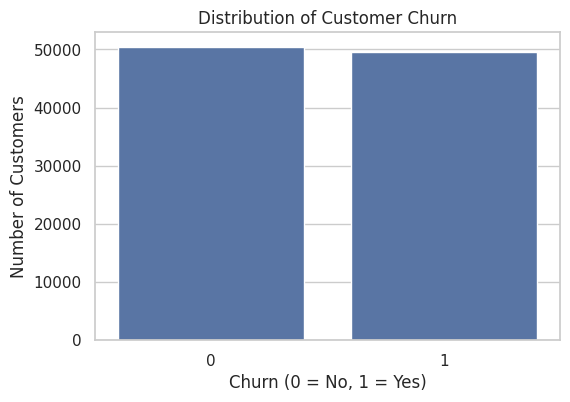

In [26]:
print("Churn distribution (%):")
print((df["churn"].value_counts(normalize=True) * 100).round(1).to_string())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="churn")
plt.title("Distribution of Customer Churn")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

Churn is split almost evenly, with 49.6% churners. A real operator loses only a small share of customers each month, so this balance most likely comes from how the sample was drawn. That has two consequences: accuracy is a fair metric here, and the churn rates in this notebook describe the sample, not the operator's customer base. I come back to the second point in the impact estimate.

## 4. Exploratory analysis

I start with how the engagement variables are distributed and how they differ between churners and non-churners. The plots cut off extreme values to stay readable, but nothing is removed from the data.

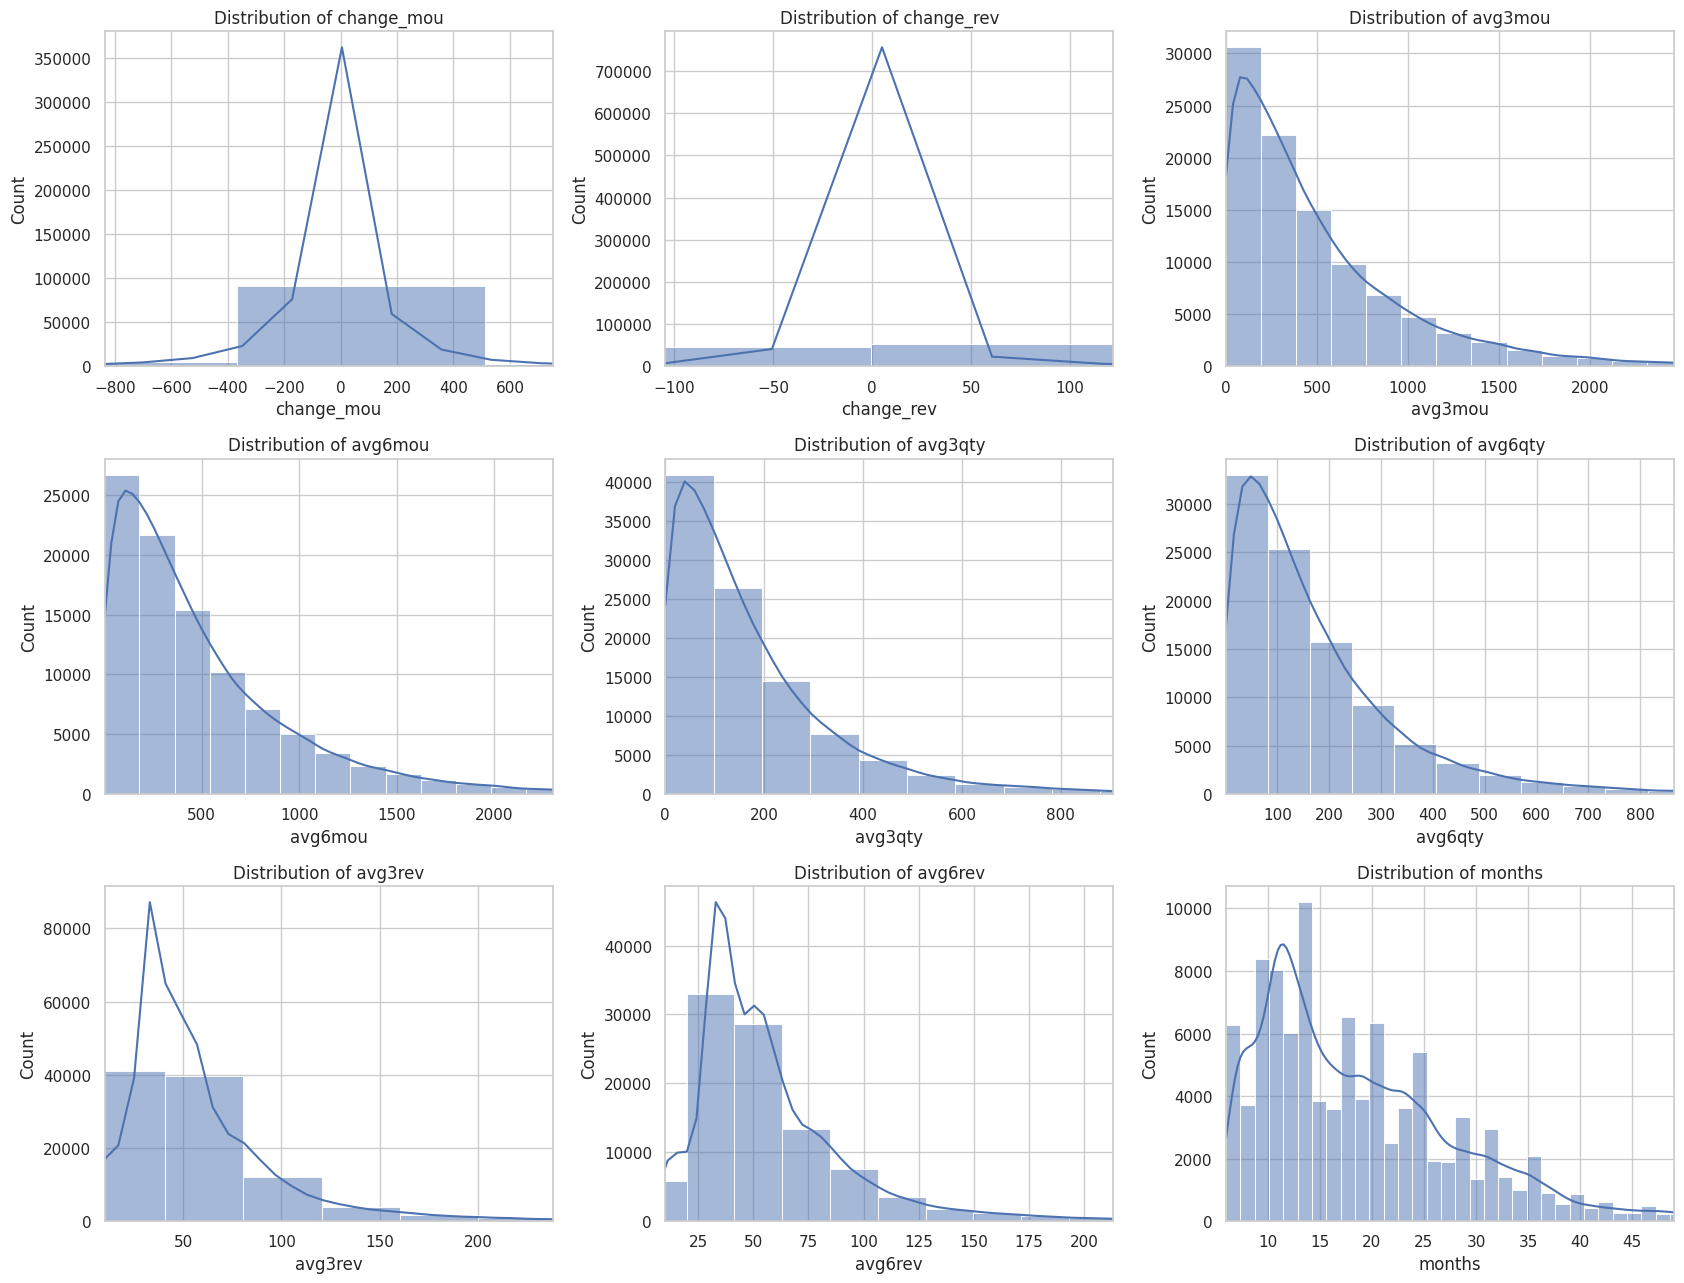

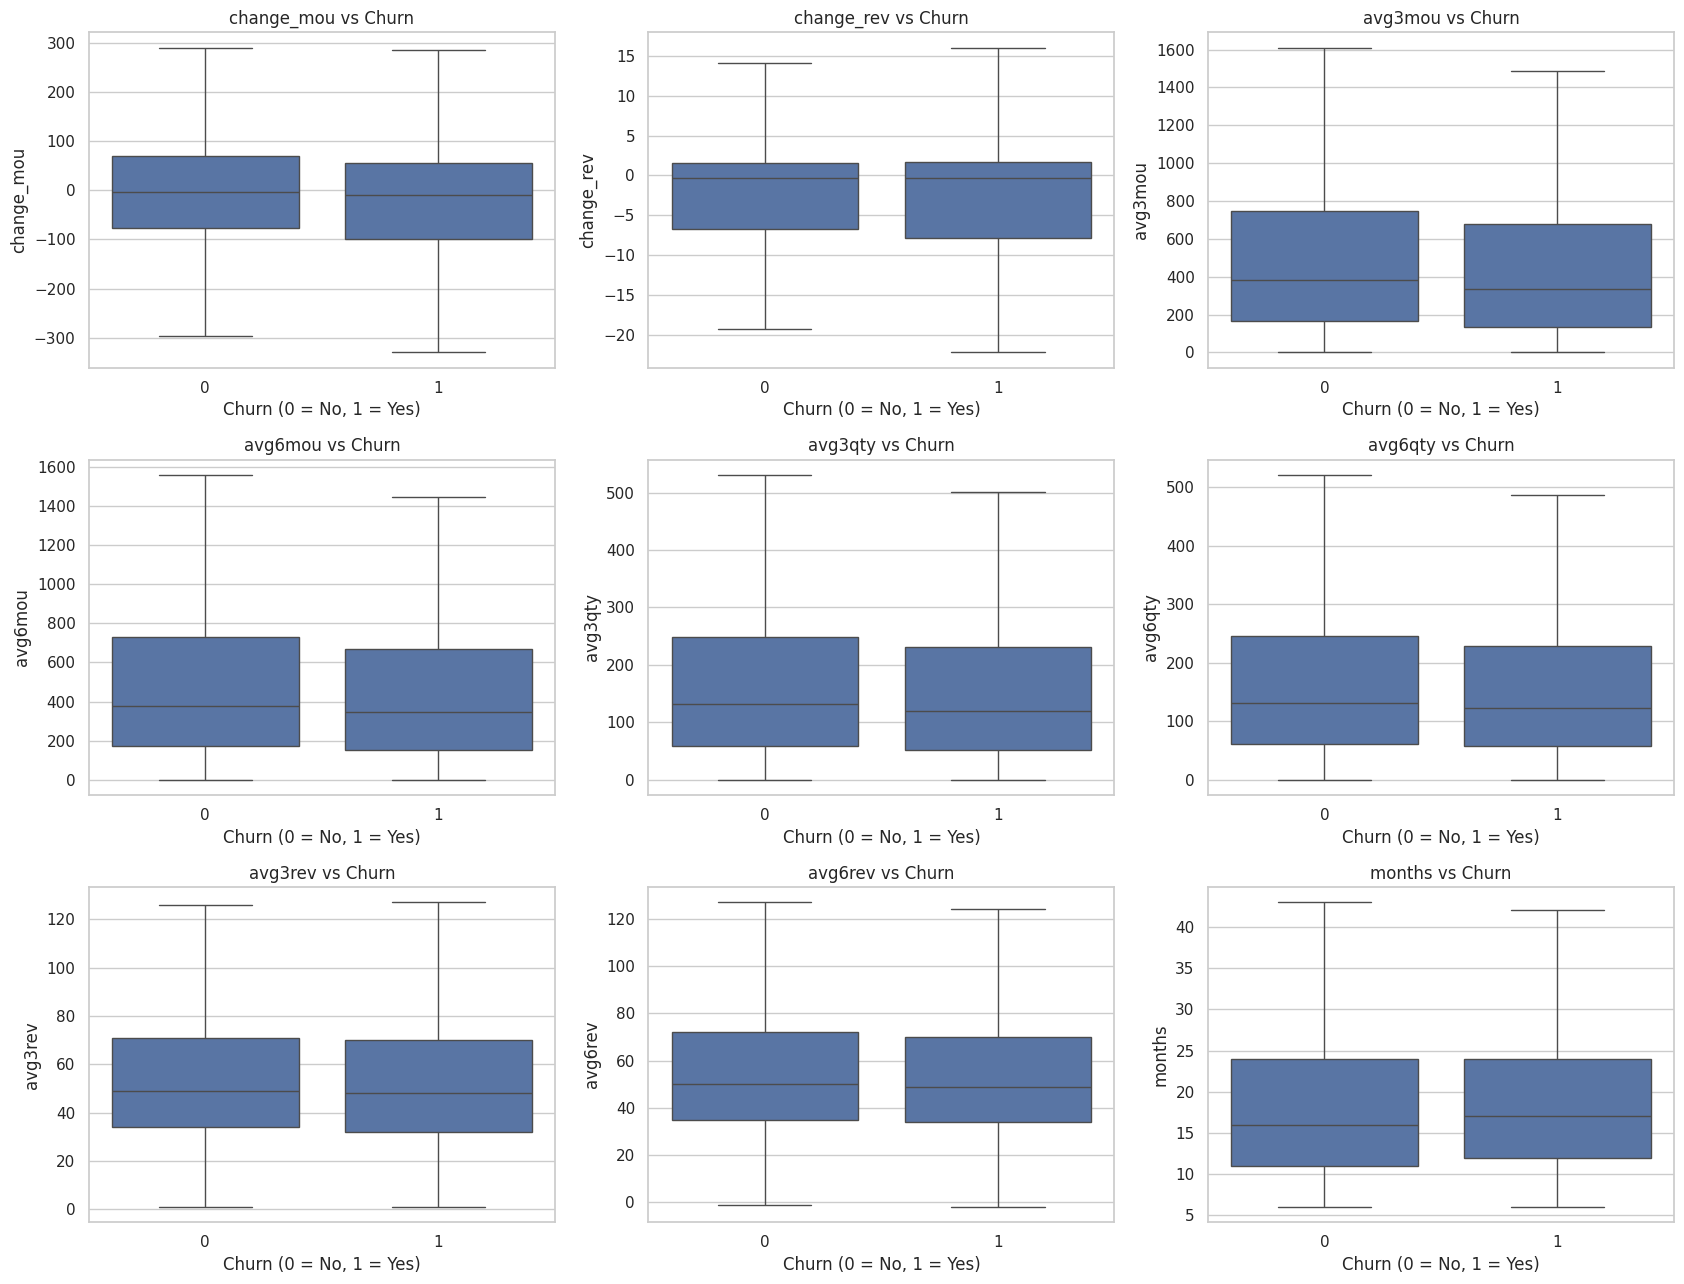

In [27]:
# Distributions (axis limits at the 1st-99th percentile; no data is removed)
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
for col, ax in zip(engagement_cols, axes.flatten()):
    sns.histplot(data=df, x=col, bins=40, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlim(df[col].quantile(0.01), df[col].quantile(0.99))
plt.tight_layout()
plt.show()

# Churners versus non-churners
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
for col, ax in zip(engagement_cols, axes.flatten()):
    sns.boxplot(data=df, x="churn", y=col, showfliers=False, ax=ax)
    ax.set_title(f"{col} vs Churn")
    ax.set_xlabel("Churn (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

Churners sit a bit lower on usage. Median `avg3mou` is 336 minutes against 380, median `change_mou` is -10 against -3, and call counts move the same way. Median revenue is almost the same (48 against 49). The differences are small and no single variable separates the two groups.

### Service quality and customer value

The right retention action depends on whether a customer is unhappy with the network, low in value or just using the service less, so I check the first two as well. The failed-call rate is dropped plus blocked calls divided by attempted calls. Customers with no attempts are left undefined instead of being set to zero.

In [28]:
# Service quality: dropped and blocked calls relative to attempts.
# Zero attempts are treated as undefined, not as zero failure.
service_cols = ["drop_vce_Mean", "blck_vce_Mean", "drop_dat_Mean",
                "blck_dat_Mean", "complete_Mean", "attempt_Mean"]
display(df.groupby("churn")[service_cols].median().T)

df["failed_call_proxy_rate"] = df["drop_blk_Mean"] / df["attempt_Mean"].replace(0, np.nan)
display(df.groupby("churn")["failed_call_proxy_rate"].agg(["count", "mean", "median"]))
print("Undefined ratios:", df["failed_call_proxy_rate"].isna().sum(),
      "| ratios above 1:", df["failed_call_proxy_rate"].gt(1).sum())

# Customer value
value_cols = ["rev_Mean", "totmrc_Mean", "totrev", "avg3rev"]
display(df.groupby("churn")[value_cols].median().T)

# Tenure and handset age comparison by churn

print("Median tenure and handset age by churn:")
display(
    df.groupby("churn")[["months", "eqpdays"]]
    .median()
    .T
)

print("Negative handset-age values:", (df["eqpdays"] < 0).sum())
print("Missing handset-age values:", df["eqpdays"].isna().sum())

churn,0,1
drop_vce_Mean,3.000000,3.000000
blck_vce_Mean,1.000000,1.000000
drop_dat_Mean,0.000000,0.000000
blck_dat_Mean,0.000000,0.000000
complete_Mean,81.333333,71.333333
attempt_Mean,107.333333,94.666667


,count,mean,median
churn,,,
0,46974,0.069861,0.053634
1,44866,0.075998,0.056548


Undefined ratios: 8160 | ratios above 1: 4


churn,0,1
rev_Mean,48.87625,47.4900
totmrc_Mean,44.99000,43.4175
totrev,784.40000,823.6550
avg3rev,49.00000,48.0000


Median tenure and handset age by churn:


churn,0,1
months,16.0,17.0
eqpdays,310.0,366.0


Negative handset-age values: 133
Missing handset-age values: 1


Failed-call rates are only slightly higher for churners (mean 7.6% of attempts against 7.0%), and median dropped and blocked voice calls are identical in both groups. Churners attempt and complete fewer calls (median 71 completed against 81), which fits with lower usage. Median monthly revenue is close (47.5 against 48.9). Lifetime revenue is higher for churners (824 against 784), probably because their tenure is a little longer (17 months against 16). Neither service quality nor revenue level separates the groups well.

## 5. Measuring decline

The six-month average covers the same months as the three-month one, so `avg3 - avg6` is a relative indicator, not a comparison of two independent periods. A negative gap means the last three months were below the six-month level. I compute absolute gaps for minutes, calls and revenue, plus relative gaps (the gap divided by the six-month level). For voice and calls the relative gap stays between -1 and +1, which makes heavy and light users comparable and keeps outliers in check. Revenue has a few extreme values where six-month revenue is close to zero.

As a first, rough check I also group customers by whether their recent average is below, above or equal to the six-month average.

In [29]:
# Absolute gap: recent three-month average minus six-month average.
# Relative gap: the same difference scaled by the six-month level, so heavy
# and light users are comparable (clip and +1 avoid division by zero).
for m in ["mou", "rev", "qty"]:
    df[f"{m}_recent_gap"] = df[f"avg3{m}"] - df[f"avg6{m}"]
    df[f"{m}_rel_gap"] = df[f"{m}_recent_gap"] / (df[f"avg6{m}"].clip(lower=0) + 1)

gap_cols = [f"{m}_{kind}" for m in ["mou", "rev", "qty"] for kind in ["recent_gap", "rel_gap"]]
display(df[gap_cols].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
mou_recent_gap,97161.0,6.578,145.314,-2528.000,-37.000,2.000,50.000,2284.0
mou_rel_gap,97161.0,-0.003,0.284,-0.999,-0.135,0.010,0.153,1.0
rev_recent_gap,97161.0,0.399,19.146,-774.000,-3.000,0.000,3.000,738.0
rev_rel_gap,97161.0,-0.000,0.199,-0.953,-0.071,0.000,0.071,9.2
qty_recent_gap,97161.0,1.174,48.628,-1110.000,-12.000,1.000,16.000,1031.0
qty_rel_gap,97161.0,-0.006,0.258,-0.998,-0.123,0.003,0.134,1.0


VOICE USAGE TREND


,Customers,Churn_Rate
mou_trend_group,,
Equal averages,1742,0.582664
Lower recent average,45110,0.512458
Higher recent average,50309,0.482776
Missing,2839,0.402254


REVENUE TREND


,Customers,Churn_Rate
rev_trend_group,,
Higher recent average,36852,0.499810
Lower recent average,41037,0.498185
Equal averages,19272,0.495901
Missing,2839,0.402254


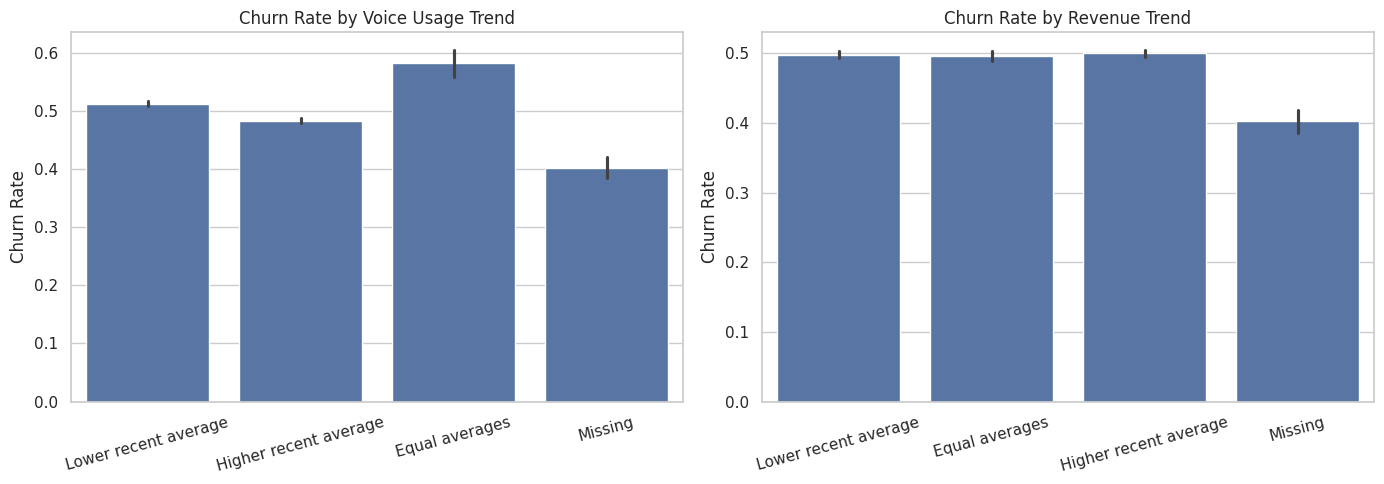

In [30]:
# A first, coarse view: is the recent average below, above or equal to the six-month average?
def classify_trend(recent, benchmark):
    result = pd.Series("Missing", index=recent.index, dtype="object")
    valid = recent.notna() & benchmark.notna()
    result.loc[valid] = np.select(
        [recent.loc[valid] < benchmark.loc[valid], recent.loc[valid] > benchmark.loc[valid]],
        ["Lower recent average", "Higher recent average"],
        default="Equal averages",
    )
    return result

df["mou_trend_group"] = classify_trend(df["avg3mou"], df["avg6mou"])
df["rev_trend_group"] = classify_trend(df["avg3rev"], df["avg6rev"])

trend_panels = [("mou_trend_group", "Voice Usage Trend"), ("rev_trend_group", "Revenue Trend")]

for col, title in trend_panels:
    print(title.upper())
    display(
        df.groupby(col)
        .agg(Customers=("churn", "count"), Churn_Rate=("churn", "mean"))
        .sort_values("Churn_Rate", ascending=False)
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (col, title) in zip(axes, trend_panels):
    sns.barplot(data=df, x=col, y="churn", ax=ax)
    ax.set_title(f"Churn Rate by {title}")
    ax.set_ylabel("Churn Rate")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

Splitting customers into lower and higher recent usage only separates churn slightly (51.2% against 48.3%). The revenue groups look the same, about 50% each. Part of the reason is that `avg3rev` and `avg6rev` are rounded to whole numbers, so 19,272 customers show identical values. These groups are also too coarse, since a 1% dip and a 50% drop land in the same bucket. So next I look at how big the decline is.

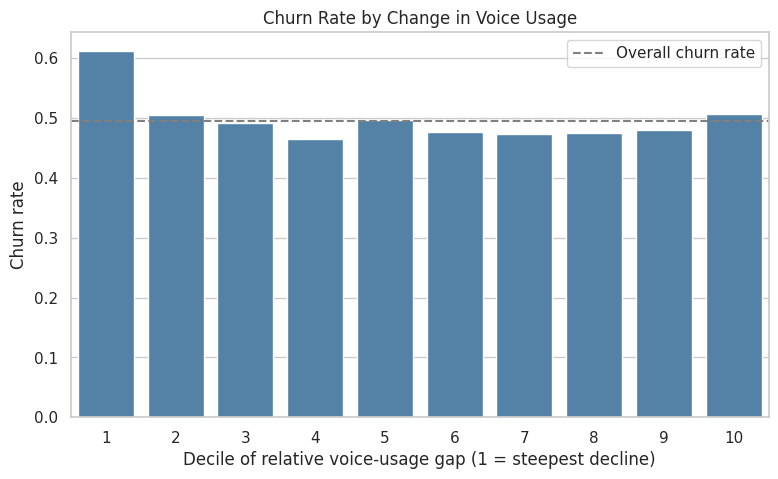

No voice usage in last 3 months: 1761 customers, churn rate 75.2%
Customers with steep voice decline: 9830
Churn rate among these customers: 61.2%


In [31]:
# Churn rate across deciles of the relative voice-usage gap (decile 1 = steepest decline)
df["mou_rel_decile"] = pd.qcut(df["mou_rel_gap"], 10, labels=False, duplicates="drop") + 1
decile_churn = df.groupby("mou_rel_decile")["churn"].mean()

plt.figure(figsize=(9, 5))
sns.barplot(x=decile_churn.index.astype(int), y=decile_churn.values, color="steelblue")
plt.axhline(df["churn"].mean(), color="grey", linestyle="--", label="Overall churn rate")
plt.xlabel("Decile of relative voice-usage gap (1 = steepest decline)")
plt.ylabel("Churn rate")
plt.title("Churn Rate by Change in Voice Usage")
plt.legend()
plt.show()

# Customers with no voice usage at all in the last three months
silent = df["avg3mou"] == 0
print(f"No voice usage in last 3 months: {silent.sum()} customers, "
      f"churn rate {df.loc[silent, 'churn'].mean():.1%}")

# Customers with at least a one-third decline in recent voice usage

steep_decline = df["mou_rel_gap"] < -0.33

print(
    "Customers with steep voice decline:",
    steep_decline.sum()
)

print(
    "Churn rate among these customers:",
    f"{df.loc[steep_decline, 'churn'].mean():.1%}"
)

Churn stays flat across most of the range (47-51%) and only rises in the first decile. Customers whose recent voice usage is at least a third below their six-month level (relative gap below -0.33) churn at 61.2%, against 49.6% overall. Mild declines carry no signal. Customers with no voice usage at all in the last three months are a smaller but sharper group: 1,761 customers (1.8%) with 75.2% churn.

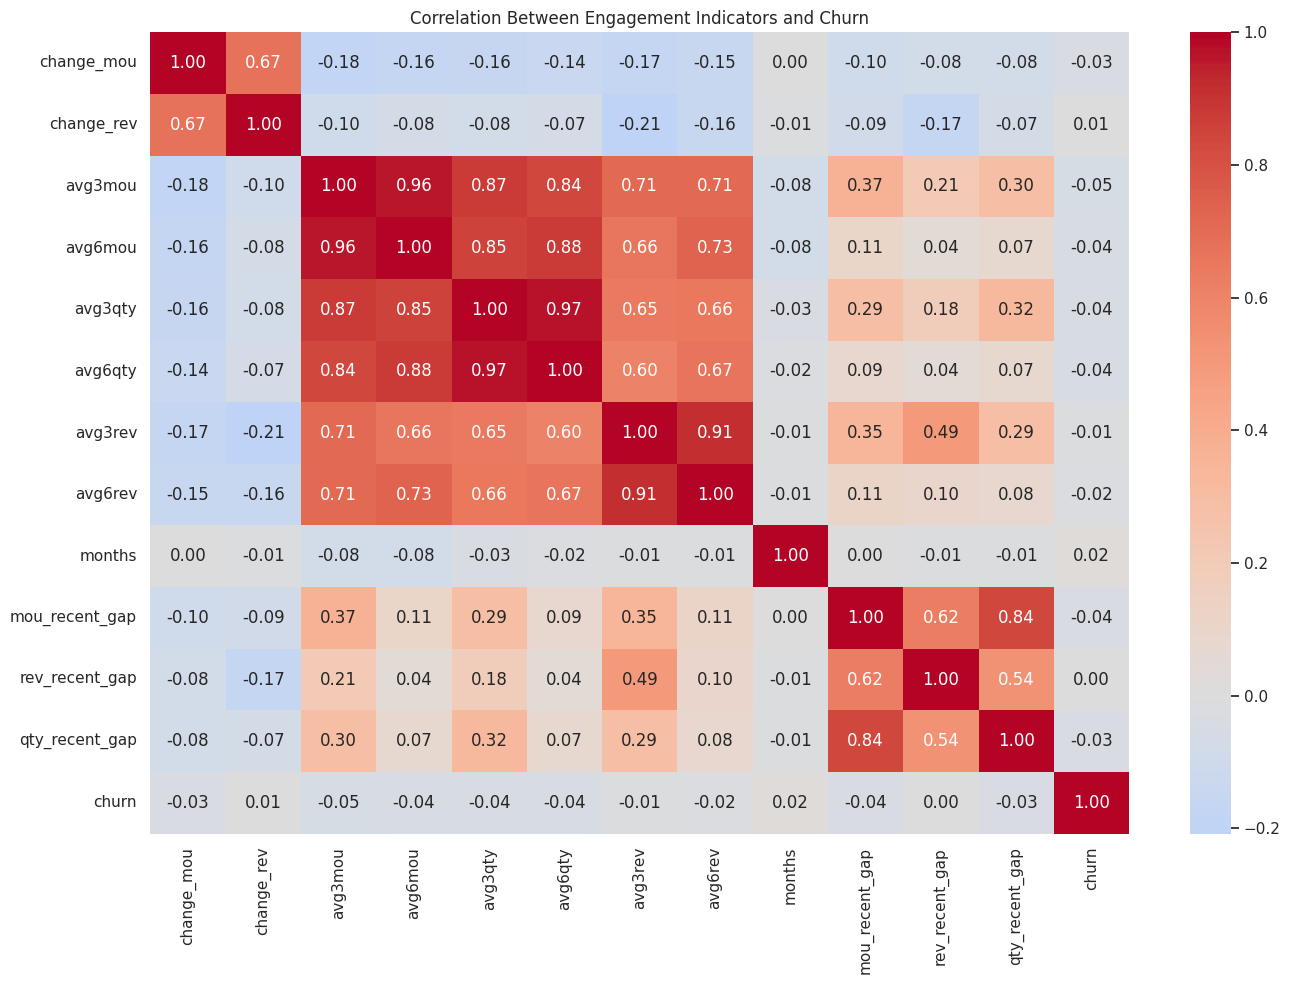

In [32]:
correlation_cols = engagement_cols + ["mou_recent_gap", "rev_recent_gap", "qty_recent_gap", "churn"]

plt.figure(figsize=(14, 10))
sns.heatmap(df[correlation_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Engagement Indicators and Churn")
plt.tight_layout()
plt.show()

### Tenure and handset age

Tenure and handset age turn out to be the two strongest predictors in the model later on, so I check how churn changes across them. Negative handset ages are treated as missing.

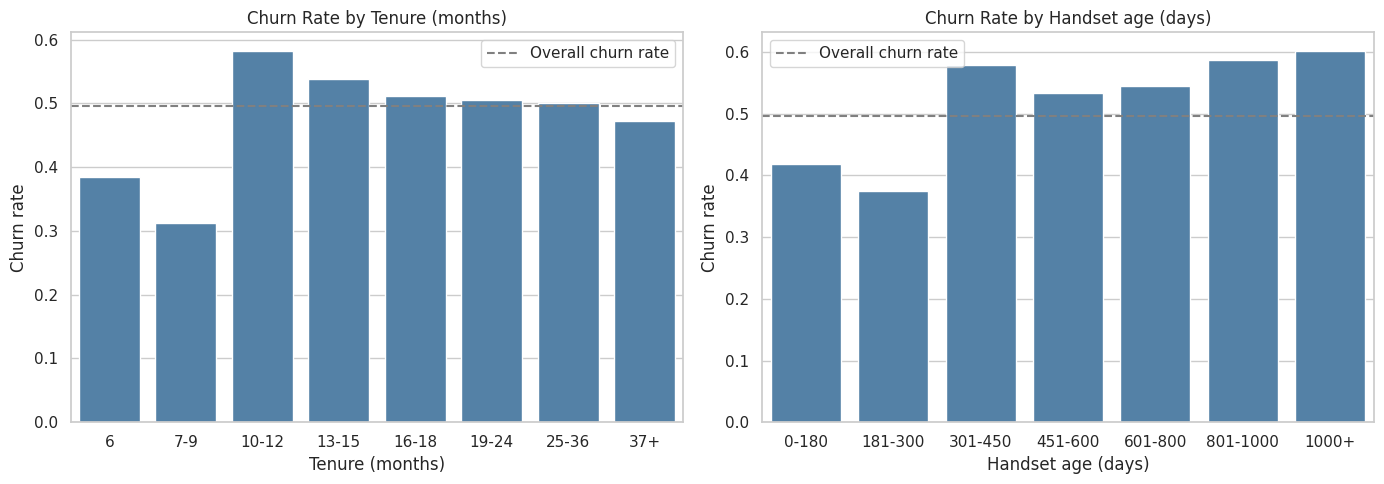

In [33]:
# Churn rate by tenure and handset age
df["tenure_band"] = pd.cut(df["months"], [0, 6, 9, 12, 15, 18, 24, 36, 100],
                           labels=["6", "7-9", "10-12", "13-15", "16-18", "19-24", "25-36", "37+"])
df["handset_band"] = pd.cut(df["eqpdays"].where(df["eqpdays"] >= 0),
                            [-1, 180, 300, 450, 600, 800, 1000, 5000],
                            labels=["0-180", "181-300", "301-450", "451-600", "601-800", "801-1000", "1000+"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in zip(axes, ["tenure_band", "handset_band"],
                          ["Tenure (months)", "Handset age (days)"]):
    rates = df.groupby(col, observed=True)["churn"].mean()
    sns.barplot(x=rates.index.astype(str), y=rates.values, color="steelblue", ax=ax)
    ax.axhline(df["churn"].mean(), color="grey", linestyle="--", label="Overall churn rate")
    ax.set_title(f"Churn Rate by {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("Churn rate")
    ax.legend()
plt.tight_layout()
plt.show()

Churn is not highest among the newest customers. It is about 31% at 7-9 months of tenure, jumps to about 58% at 10-12 months and then slowly falls to about 47% beyond three years. Handset age shows a similar step: churn is 37-42% up to about 300 days and 53-60% above it, reaching 60% beyond 1,000 days. Together this looks like a renewal or upgrade window around the one-year mark. The data says nothing about contracts, though, so this is a hypothesis to test, not a finding.

### Summary of the exploratory analysis

- Each engagement variable is only weakly related to churn. The strongest linear correlation is -0.05 (`avg3mou`).
- Decline matters when it is steep or total. Small movements are noise.
- Revenue trends and call-failure rates barely differ between churners and non-churners.
- Short-tenure customers lack six-month history, so I handle them with flags, not zeros.
- Churn peaks at 10-12 months of tenure (58%, against 31% at 7-9 months) and steps up above about 300 days of handset age (53-60%, against 37-42%). Handset age is also higher for churners (median 366 against 310 days), so I add it as a profile feature.

## 6. Modelling

I use three groups of features: profile (tenure and handset age), usage levels (3- and 6-month averages of minutes, calls and revenue) and decline measures (`change_mou`, `change_rev` and the absolute and relative gaps), plus the missing-history flags. The split is 80/20, stratified on churn, and each pipeline fits its median imputer on the training data only.

I compare logistic regression as a baseline against random forest and gradient boosting, since tree models can pick up threshold effects like the one above. ROC-AUC is the main metric because the end use is ranking customers by risk. I also report accuracy since the classes are balanced.

In [34]:
# Feature groups
profile_cols = ["months", "eqpdays"]
level_cols = ["avg3mou", "avg6mou", "avg3qty", "avg6qty", "avg3rev", "avg6rev"]
decline_cols = [
    "change_mou", "change_rev",
    "mou_recent_gap", "rev_recent_gap", "qty_recent_gap",
    "mou_rel_gap", "rev_rel_gap", "qty_rel_gap",
]
feature_cols = profile_cols + level_cols + decline_cols

six_month_cols = ["avg6mou", "avg6qty", "avg6rev"] + [
    f"{m}_{kind}" for m in ["mou", "rev", "qty"] for kind in ["recent_gap", "rel_gap"]
]

def build_features(cols):
    """Select columns and add flags for missing six-month / change history."""
    X = df[cols].copy()
    if "eqpdays" in cols:
        X.loc[X["eqpdays"] < 0, "eqpdays"] = np.nan      # negative days are invalid
    if any(c in cols for c in six_month_cols):
        X["six_month_history_missing"] = (
            df[["avg6mou", "avg6qty", "avg6rev"]].isna().any(axis=1).astype(int)
        )
    if any(c in cols for c in ["change_mou", "change_rev"]):
        X["change_metrics_missing"] = (
            df[["change_mou", "change_rev"]].isna().any(axis=1).astype(int)
        )
    return X.replace([np.inf, -np.inf], np.nan)

X = build_features(feature_cols)
y = df["churn"].astype(int)

# 80/20 split, stratified on churn
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Features:", X.shape[1])
print("Training customers:", X_train.shape[0], "| test customers:", X_test.shape[0])
print("Churn rate - train: {:.3f} | test: {:.3f}".format(y_train.mean(), y_test.mean()))

Features: 18
Training customers: 80000 | test customers: 20000
Churn rate - train: 0.496 | test: 0.496


In [35]:
def make_rf():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300, max_depth=14, min_samples_leaf=10,
            max_features="sqrt", random_state=42, n_jobs=-1)),
    ])

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42)),
    ]),
    "Random Forest": make_rf(),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", GradientBoostingClassifier(
            n_estimators=150, learning_rate=0.05, max_depth=3,
            min_samples_leaf=20, random_state=42)),
    ]),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
    })

comparison_df = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

# Continue with the model that ranks customers best
best_model_name = comparison_df.loc[0, "Model"]
best_model = models[best_model_name]
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]
print("Selected model:", best_model_name)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Random Forest,0.6112,0.6031,0.6302,0.6164,0.6609,0.6485
1,Gradient Boosting,0.6050,0.5925,0.6503,0.6201,0.6545,0.6439
2,Logistic Regression,0.5661,0.5635,0.5527,0.5580,0.5902,0.5774


Selected model: Random Forest


Random forest scores highest on ROC-AUC (0.661, accuracy 61.1%), with gradient boosting close behind (about 0.65) and logistic regression well below (0.590). That gap fits the earlier finding that decline works as a threshold effect, which a linear model can't represent. Performance is modest, so churn is only partly predictable from these variables. I go ahead with the random forest.

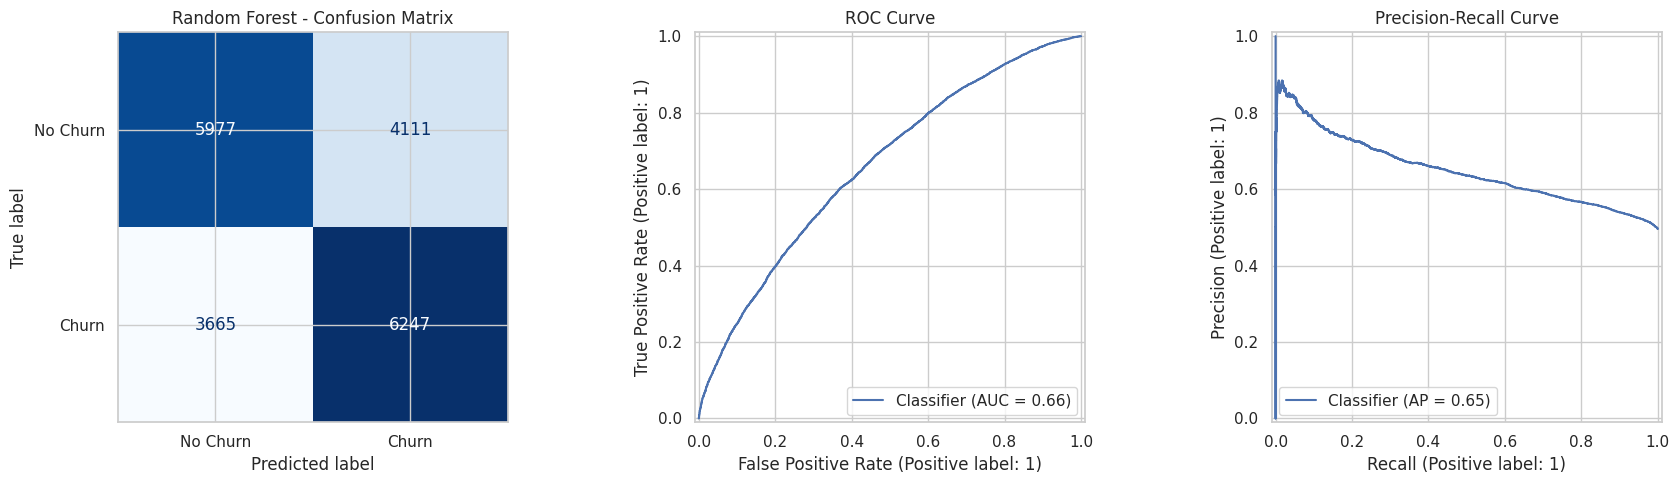

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["No Churn", "Churn"]).plot(
    ax=axes[0], cmap="Blues", values_format="d", colorbar=False
)
axes[0].set_title(f"{best_model_name} - Confusion Matrix")

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[2])
axes[2].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

The model finds 63% of churners (recall) and is right about 60% of the time when it flags one (precision). Out of 20,000 test customers it still misclassifies roughly 4,100 non-churners and 3,700 churners. A ROC-AUC of 0.661 means a randomly picked churner is ranked above a randomly picked non-churner 66% of the time. That's good enough for prioritising customers, not for deciding any single customer's fate.

### Which features drive the predictions?

Permutation importance is the drop in ROC-AUC when a feature's values are shuffled.

,Feature,Importance,Std
1,eqpdays,0.0565,0.0021
0,months,0.0497,0.0028
8,change_mou,0.0338,0.0022
9,change_rev,0.0128,0.0012
2,avg3mou,0.0068,0.0013
13,mou_rel_gap,0.0045,0.0017
15,qty_rel_gap,0.0043,0.0007
17,change_metrics_missing,0.0036,0.0009
3,avg6mou,0.0031,0.0012
4,avg3qty,0.0028,0.0010


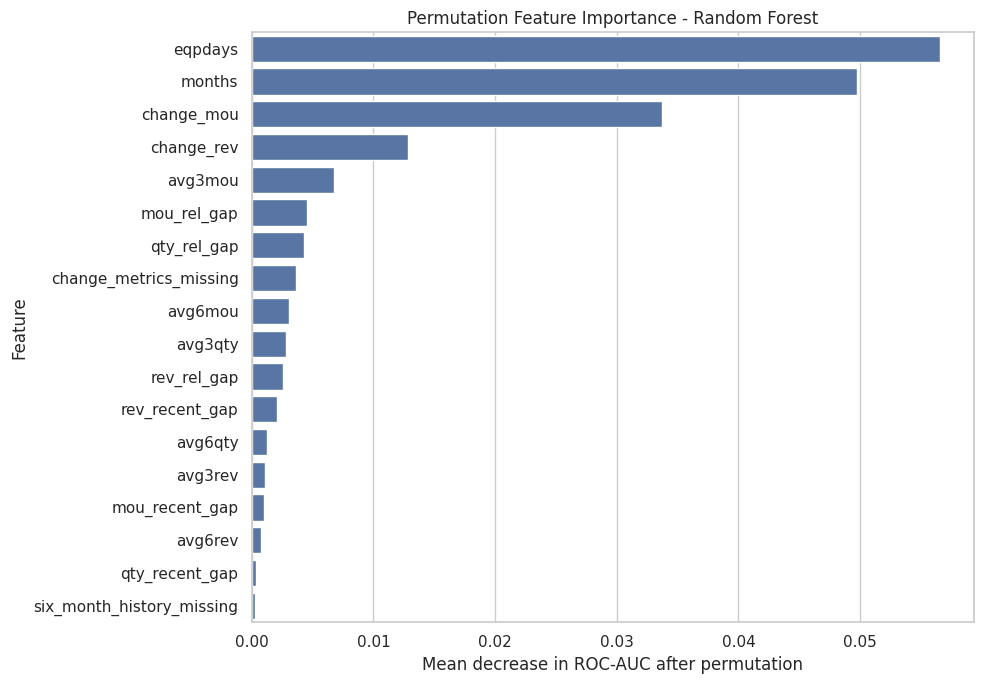

In [37]:
# Permutation importance on a 5,000-customer sample of the test set
sample = X_test.sample(n=5000, random_state=42)

result = permutation_importance(
    best_model, sample, y_test.loc[sample.index],
    n_repeats=5, random_state=42, scoring="roc_auc", n_jobs=-1,
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean,
    "Std": result.importances_std,
}).sort_values("Importance", ascending=False)

display(importance_df.head(10).round(4))

plt.figure(figsize=(10, 7))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title(f"Permutation Feature Importance - {best_model_name}")
plt.xlabel("Mean decrease in ROC-AUC after permutation")
plt.tight_layout()
plt.show()

Handset age (0.057) and tenure (0.050) lead, followed by `change_mou` (0.034) and `change_rev` (0.013). Everything else is below 0.007. Correlated usage features share credit, so their individual scores understate what the group adds, and the next test measures that directly. These are associations, not causes.

### Do the decline measures add value?

To answer the second question directly, I train the same random forest on progressively richer feature sets, on the same split, and compare ROC-AUC.

In [38]:
# Same Random Forest, same split; one feature group added at a time
feature_sets = {
    "Tenure only": ["months"],
    "Tenure + handset age": profile_cols,
    "+ usage levels": profile_cols + level_cols,
    "+ decline measures (full model)": feature_cols,
}

rows = []
for name, cols in feature_sets.items():
    X_set = build_features(cols)
    rf = make_rf().fit(X_set.loc[X_train.index], y_train)
    prob = rf.predict_proba(X_set.loc[X_test.index])[:, 1]
    rows.append({"Feature set": name, "Features": X_set.shape[1],
                 "ROC-AUC": roc_auc_score(y_test, prob)})

ablation_df = pd.DataFrame(rows)
ablation_df["Gain vs previous row"] = ablation_df["ROC-AUC"].diff()
display(ablation_df.round(4))

# Five-fold cross-validation of the same comparison (checks the gain is not a one-split result)
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, cols in {"Without decline measures": profile_cols + level_cols,
                   "With decline measures": feature_cols}.items():
    scores = cross_val_score(make_rf(), build_features(cols), y, cv=skf, scoring="roc_auc")
    cv_rows.append({"Feature set": name, "CV ROC-AUC": scores.mean(), "Std": scores.std()})
display(pd.DataFrame(cv_rows).round(4))

,Feature set,Features,ROC-AUC,Gain vs previous row
0,Tenure only,1,0.5946,NaN
1,Tenure + handset age,2,0.6167,0.0221
2,+ usage levels,9,0.6383,0.0216
3,+ decline measures (full model),18,0.6609,0.0226


,Feature set,CV ROC-AUC,Std
0,Without decline measures,0.6366,0.0035
1,With decline measures,0.6577,0.0030


In [39]:
# Upper-bound check: same random forest on every numeric column plus the gap measures
numeric_cols = [c for c in client_df.select_dtypes("number").columns.tolist()
                + record_df.select_dtypes("number").columns.tolist()
                if c not in ("churn", "Customer_ID")] + gap_cols
X_all = df[numeric_cols].replace([np.inf, -np.inf], np.nan)
rf_all = make_rf().fit(X_all.loc[X_train.index], y_train)
auc_all = roc_auc_score(y_test, rf_all.predict_proba(X_all.loc[X_test.index])[:, 1])
print(f"All {len(numeric_cols)} numeric columns: ROC-AUC {auc_all:.4f} vs 0.6609 for the 18-feature model")

All 83 numeric columns: ROC-AUC 0.6732 vs 0.6609 for the 18-feature model


Each feature group helps: tenure alone gives 0.595, adding handset age lifts it to 0.617, usage levels to 0.638, and decline measures to 0.661. The decline measures add 0.0226 (0.6383 to 0.6609), so declining engagement carries extra information beyond tenure, handset age and usage levels. Five-fold cross-validation backs this up: ROC-AUC goes from 0.637 (± 0.004) to 0.658 (± 0.003), and decline helps in every fold. Overall, decline is a real but modest contributor, not a standalone predictor. A random forest on all 83 numeric columns reaches 0.673, so the compact feature set gives up little.

## 7. Risk ranking

Each test-set customer gets a churn probability. I rank them by it and split them into the highest-risk 20%, the next 30% and the lower 50%. This shows whether the ranking separates actual churn and what the high-risk customers look like.

In [40]:
# Customer-level risk table for the test set
risk_results = pd.DataFrame({
    "Customer_ID": df.loc[X_test.index, "Customer_ID"].values,
    "Actual_Churn": y_test.values,
    "Churn_Probability": y_prob,
    "Monthly_Revenue_Proxy": df.loc[X_test.index, "rev_Mean"].values,
}, index=X_test.index)

# Rank by predicted risk and split into three groups
risk_results["Risk_Percentile"] = risk_results["Churn_Probability"].rank(method="first", pct=True)
risk_results["Risk_Group"] = pd.cut(
    risk_results["Risk_Percentile"],
    bins=[0, 0.50, 0.80, 1.00],
    labels=["Lower 50%", "Middle 30%", "Highest-risk 20%"],
    include_lowest=True,
)
risk_results = risk_results.sort_values("Churn_Probability", ascending=False)

# Behavioural profile of each group
risk_results["Tenure_Months"] = X_test["months"]
risk_results["MOU_Recent_Gap"] = X_test["mou_recent_gap"]
risk_results["Revenue_Recent_Gap"] = X_test["rev_recent_gap"]
risk_results["Change_MOU"] = X_test["change_mou"]
risk_results["Failed_Call_Proxy_Rate"] = df.loc[X_test.index, "failed_call_proxy_rate"]

print("Churn by risk group:")
display(
    risk_results.groupby("Risk_Group", observed=False).agg(
        Customers=("Actual_Churn", "size"),
        Actual_Churners=("Actual_Churn", "sum"),
        Observed_Churn_Rate=("Actual_Churn", "mean"),
        Average_Predicted_Risk=("Churn_Probability", "mean"),
    ).round(3)
)

print("\nMedian characteristics by risk group:")
display(
    risk_results.groupby("Risk_Group", observed=False)[
        ["Tenure_Months", "MOU_Recent_Gap", "Revenue_Recent_Gap",
         "Change_MOU", "Failed_Call_Proxy_Rate", "Monthly_Revenue_Proxy"]
    ].median().round(3)
)

Churn by risk group:


,Customers,Actual_Churners,Observed_Churn_Rate,Average_Predicted_Risk
Risk_Group,,,,
Lower 50%,10000,3823,0.382,0.401
Middle 30%,6000,3300,0.550,0.544
Highest-risk 20%,4000,2789,0.697,0.665



Median characteristics by risk group:


,Tenure_Months,MOU_Recent_Gap,Revenue_Recent_Gap,Change_MOU,Failed_Call_Proxy_Rate,Monthly_Revenue_Proxy
Risk_Group,,,,,,
Lower 50%,16.0,8.0,0.0,4.25,0.055,50.450
Middle 30%,19.0,4.0,0.0,-9.25,0.054,43.691
Highest-risk 20%,13.0,-14.0,0.0,-42.75,0.056,44.543


Observed churn rises with predicted risk: 38.2% in the lower half, 55.0% in the middle group and about 70% in the highest-risk 20%. The highest-risk group sits close to the one-year mark (median tenure 13 months against 16 and 19), with falling voice usage (median gap of -14 minutes against +8 in the lower half, and `change_mou` of -43 against +4) and flat revenue gaps. Failed-call rates are the same in all three groups (about 5.5%), so service quality doesn't tell us who is at risk in this data.

## 8. Impact scenarios

This estimate is illustrative. Three inputs are assumed, not measured: the share of contacted churners a retention offer saves (10-30%), the margin on retained revenue (30%) and how long a saved customer stays (12 months). Churn in this sample (about 50%) is also far above what an operator sees, so I rescale precision among contacted customers to an assumed real churn rate of 2% per month, using the odds ratio the model achieves in the sample. The main output is the break-even cost per contact, meaning the most a single offer can cost before the campaign loses money. These are scenario values, not measurements, and the slides give the market sources behind them.

In [41]:
# Scenario assumptions (market sources for these are in the slides)
sample_churn_rate = y.mean()   # churn rate in this dataset
real_churn_rate = 0.02         # assumed monthly churn in a typical customer base
margin_pct = 0.30              # share of revenue kept as contribution margin
months_retained = 12           # months a saved customer is assumed to stay
target_shares = [0.05, 0.10, 0.20]
save_rates = [0.10, 0.20, 0.30]

def adjust_precision(p, sample_rate, real_rate):
    """Re-weight precision from this dataset's churn rate to an assumed real one."""
    odds = (p / (1 - p)) * (real_rate / (1 - real_rate)) / (sample_rate / (1 - sample_rate))
    return odds / (1 + odds)

rows = []
for share in target_shares:
    k = int(np.ceil(len(risk_results) * share))
    top = risk_results.nlargest(k, "Churn_Probability")

    p_dataset = top["Actual_Churn"].mean()
    p_adjusted = adjust_precision(p_dataset, sample_churn_rate, real_churn_rate)
    value_per_save = top["Monthly_Revenue_Proxy"].mean() * margin_pct * months_retained

    for save in save_rates:
        rows.append({
            "Target share": f"{share:.0%}",
            "Customers contacted": k,
            "Precision (dataset)": p_dataset,
            "Precision (adjusted)": p_adjusted,
            "Save rate": f"{save:.0%}",
            "Saved per 1,000 contacts": 1000 * p_adjusted * save,
            "Break-even cost per contact": p_adjusted * save * value_per_save,
        })

impact_df = pd.DataFrame(rows)
display(impact_df.round(3))

,Target share,Customers contacted,Precision (dataset),Precision (adjusted),Save rate,"Saved per 1,000 contacts",Break-even cost per contact
0,5%,1000,0.802,0.078,10%,7.760,1.120
1,5%,1000,0.802,0.078,20%,15.519,2.239
2,5%,1000,0.802,0.078,30%,23.279,3.359
3,10%,2000,0.747,0.058,10%,5.778,0.980
4,10%,2000,0.747,0.058,20%,11.556,1.960
5,10%,2000,0.747,0.058,30%,17.334,2.940
6,20%,4000,0.697,0.046,10%,4.565,0.874
7,20%,4000,0.697,0.046,20%,9.130,1.748
8,20%,4000,0.697,0.046,30%,13.695,2.622


In [42]:
# Worked scenario: 100,000 customers, top 10% by risk, one month of churn
base_customers = 100_000
share, save_rate, cost_per_contact = 0.10, 0.20, 0.50   # cost per contact is an assumption

row = impact_df[(impact_df["Target share"] == "10%") & (impact_df["Save rate"] == "20%")].iloc[0]
contacted = base_customers * share
saved = contacted * row["Precision (adjusted)"] * save_rate
value_per_save = row["Break-even cost per contact"] / (row["Precision (adjusted)"] * save_rate)
margin_retained = saved * value_per_save
campaign_cost = contacted * cost_per_contact

print(f"Customers contacted: {contacted:,.0f}")
print(f"Churners saved: {saved:,.0f}")
print(f"Margin retained: {margin_retained:,.0f}")
print(f"Campaign cost: {campaign_cost:,.0f}")
print(f"Net benefit: {margin_retained - campaign_cost:,.0f}")

Customers contacted: 10,000
Churners saved: 116
Margin retained: 19,599
Campaign cost: 5,000
Net benefit: 14,599


To make this concrete, take a base of 100,000 customers, contact the top 10% by risk, and assume a 20% save rate and a cost of 0.50 per contact. That's about 10,000 customers contacted and roughly 116 churners saved. The margin retained is about 19,600 against a campaign cost of 5,000, so the net benefit is about 14,600 over one month of churn. At about 1.96 per contact the campaign breaks even. Every input here is an assumption.

With a 2% base churn rate, precision among contacted customers drops from about 80% in the sample to somewhere between roughly 8% (top 5%) and 5% (top 20%). Break-even cost per contact is low as a result, about 0.9 to 3.4 currency units depending on the share targeted and the save rate, and it's highest for the narrowest targeting. Under these assumptions the model supports low-cost, automated outreach to the top 5-10% by risk, not big discounts. Every figure depends on the assumptions above, and only a controlled pilot with a holdout group would measure the real effect.

## 9. Conclusions

**Findings**

- Declining engagement is a real but modest churn signal, and it matters when steep: customers whose voice usage fell by a third or more churn at 61%, and those with no usage in the last three months at 75%.
- Adding decline measures to tenure, handset age and usage levels raises ROC-AUC from 0.638 to 0.661. The selected model, a random forest, reaches ROC-AUC 0.661 and accuracy 61.1%.
- The highest-risk 20% of customers churn at about 70% against 38% in the lower half. They are mostly customers near the one-year mark whose voice usage is falling.
- Churn steps up at 10-12 months of tenure (58%, against 31% at 7-9 months) and above about 300 days of handset age (53-60%, against 37-42%), which may point to a renewal or upgrade window.
- Revenue trends and call-failure rates don't separate churners in this data.

**Recommendations**

- Contact customers with a steep voice decline or no recent usage first, with re-engagement or usage-based offers.
- Run a renewal-window programme for customers at 10-15 months of tenure, when churn is highest.
- Test handset-upgrade offers for handsets older than about 300 days, where churn steps up and which is the top-ranked feature (a hypothesis, not a result).
- Keep retention contacts cheap, since the economics depend on contact cost.
- Don't build a service-quality programme on this evidence.

**Limitations**

- I only have 3- and 6-month averages, not monthly histories, and the two windows overlap.
- The sample's churn rate is about 50%, so impact figures rely on assumed real-world churn, margin and save rate.
- Predictive power is modest and the results are associations, not causes. I tuned the models lightly and picked the best one on the same test set I report on, and the top two are close. Cross-validation confirms the value of the decline measures for the random forest, not the choice between models.
- The effect of any intervention is unmeasured. A pilot with a control group is the next step.